In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/oddrationale/mnist-in-csv/mnist_test.csv
/kaggle/input/datasets/oddrationale/mnist-in-csv/mnist_train.csv


In [2]:
df  = pd.read_csv('/kaggle/input/datasets/oddrationale/mnist-in-csv/mnist_train.csv')

In [3]:
df.head()

,label,1x1,1x2,1x3,1x4,1x5,1x6,1x7,1x8,1x9,...,28x19,28x20,28x21,28x22,28x23,28x24,28x25,28x26,28x27,28x28
0,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [4]:
df.shape

(60000, 785)

In [5]:
x = df.iloc[:,1:]
y = df.iloc[:,0]

In [18]:
from sklearn.model_selection import train_test_split
train_x,test_x,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [8]:
from sklearn.preprocessing import StandardScaler

In [9]:
scalar = StandardScaler()
x_train = scalar.fit_transform(train_x)
x_test = scalar.transform(test_x)

In [19]:
from sklearn.decomposition import PCA

In [46]:
pca = PCA(n_components=120)

In [47]:
x_train_trf = pca.fit_transform(x_train)
x_test_trf = pca.transform(x_test)

In [48]:
from sklearn.linear_model import LogisticRegression

In [49]:
lr = LogisticRegression(multi_class='multinomial')

In [50]:
lr.fit(x_train_trf,y_train)

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(multi_class='multinomial')

In [51]:
y_pred = lr.predict(x_test_trf)

In [52]:
from sklearn.metrics import accuracy_score,confusion_matrix

In [53]:
accuracy_score(y_test,y_pred)

0.9211666666666667

In [54]:
confusion_matrix(y_test,y_pred)

array([[1131,    0,    3,    1,    3,    9,   10,    2,   12,    4],
       [   0, 1281,    9,    9,    1,    4,    1,    1,   13,    3],
       [   1,   13, 1065,   11,   12,    9,   16,   15,   27,    5],
       [   2,    5,   29, 1080,    1,   46,    3,   13,   27,   13],
       [   4,    3,    6,    1, 1105,    4,   10,    5,    6,   32],
       [  12,    7,   16,   31,   13,  967,   14,    2,   36,    6],
       [  12,    1,   11,    0,    8,   10, 1126,    2,    7,    0],
       [   3,    7,   18,    9,   12,    2,    0, 1211,    3,   34],
       [   8,   21,   16,   33,    4,   38,   10,    2, 1016,   12],
       [   6,    4,    7,   16,   31,    8,    0,   43,    7, 1072]])

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/mlxtend/plotting/decision_regions.py:346: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(


<Axes: >

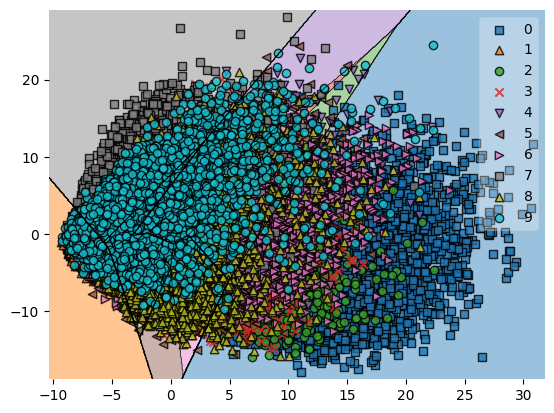

In [60]:
pca = PCA(n_components=2)
X_2d = pca.fit_transform(x_train_trf)

lr.fit(X_2d, y_train)

plot_decision_regions(X_2d, y_train.values, clf=lr)